## Features Selecting & Modelling


In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional
import lightgbm as lgb
import datetime
from statsmodels.tsa.stattools import acf
import importlib
from IPython.display import clear_output
# Self-defined functions
import data_processing_func as dpf
import ts_models
"""
importlib.reload(my_module)
"""

'\nimportlib.reload(my_module)\n'

In [74]:
importlib.reload(ts_models)

<module 'ts_models' from 'c:\\Users\\antho\\文件\\VS Code\\python proj\\GECC_Data_Analysis\\notebooks\\ts_models.py'>

In [75]:
import ts_models

In [76]:
raw = pd.read_csv(r"C:\Users\antho\文件\VS Code\python proj\GECC_Data_Analysis\data\occupancy_records_18_10_2026.csv")

In [77]:
# Database Data processing
"""
Remark:
entry_exit_data = {entry, exit} varibles , occupancy_data = occupancy counted by hours

"""
entry_exit_data ,occupancy_data = dpf.data_reshape(raw)

y_entry, x_entry =entry_exit_data.loc[:,"Entry"], dpf._features(entry_exit_data.loc[:,"Entry"], overrides = {})

y_exit, x_exit =abs(entry_exit_data.loc[:,"Exit"]), dpf._features(abs(entry_exit_data.loc[:,"Exit"]), overrides = {})

y_occ, x_occ = occupancy_data.fillna(0), dpf._features(occupancy_data.fillna(0), overrides = {})

In [78]:
est = ts_models.SFEstimator(models = ts_models.models,
                            freq='h',
                            )

In [79]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error
raw_result = []
rows = []

series = y_occ
tscv = TimeSeriesSplit(n_splits=4)
for fold, (train_idx, test_idx) in enumerate(tscv.split(series), start=1):
    train = series.iloc[train_idx]
    test = series.iloc[test_idx]

    est.fit(train)
    yhat = est.predict(len(test))    
    raw_result.append(yhat)

    # index preds by datetime and drop 'ds' col
    yhat = yhat.set_index(pd.to_datetime(yhat['ds'])).drop(columns=['ds','unique_id']).sort_index()

    # ensure test index is datetime and get its values as a Series
    test_idxed = test.copy()
    test_idxed.index = pd.to_datetime(test_idxed.index)
    # coerce test values to numeric (non-convertible -> NaN)
    test_numeric = pd.to_numeric(test_idxed.values.ravel(), errors='coerce')
    test_series = pd.Series(test_numeric, index=test_idxed.index)

    # align predictions to test index
    preds = yhat.reindex(test_series.index)

    for col in preds.columns:
        pred_numeric = pd.to_numeric(preds[col].values, errors='coerce')
        pred_series = pd.Series(pred_numeric, index=preds.index)

        # keep only positions where both truth and pred are numeric
        mask = test_series.notna() & pred_series.notna()
        if mask.sum() == 0:
            rmse = np.nan
        else:
            rmse = root_mean_squared_error(test_series[mask], pred_series[mask])

        rows.append({'fold': fold, 'model': col, 'rmse': rmse})

rmse_result = pd.DataFrame(rows)
rmse_pivot = rmse_result.pivot(index='fold', columns='model', values='rmse')
clear_output()

In [80]:
print("Test Datasets Stats")
print(f"full series: test range[Min,Max]: [{series.min()}, {series.max()}] , mean: {series.mean()} , sd: {series.std()}"
      )
# inspect one fold's test true values range
for fold,(train_idx,test_idx) in enumerate(tscv.split(series), start=1):
    test = series.iloc[test_idx]
    print(f"fold {fold} test range[Min,Max]: [{test.min()}, {test.max()}] , mean: {test.mean()} , sd: {test.std()}")
    
print()
print(rmse_pivot)

Test Datasets Stats
full series: test range[Min,Max]: [0.0, 493.7866666666667] , mean: 98.23963339052537 , sd: 116.09191280431405
fold 1 test range[Min,Max]: [0.0, 364.0862944162437] , mean: 99.01894878642582 , sd: 119.46916685501604
fold 2 test range[Min,Max]: [0.0, 324.33970276008495] , mean: 76.95467648092374 , sd: 92.13337237201976
fold 3 test range[Min,Max]: [0.0, 396.21205357142856] , mean: 73.06310232957055 , sd: 103.52486107669024
fold 4 test range[Min,Max]: [0.0, 257.71398305084745] , mean: 66.46902825725923 , sd: 82.14014452875499

model   AutoARIMA     AutoETS   AutoTBATS   AutoTheta         CES  \
fold                                                                
1      124.158833  121.713967  205.267065  153.522454  134.713084   
2       66.084985   66.084985   86.522721   74.708694   66.364245   
3      123.185771  123.183959  121.289216  116.200227  101.118717   
4      120.083567  120.083550   72.729108  125.467359  120.104549   

model  DynamicOptimizedTheta  Histori

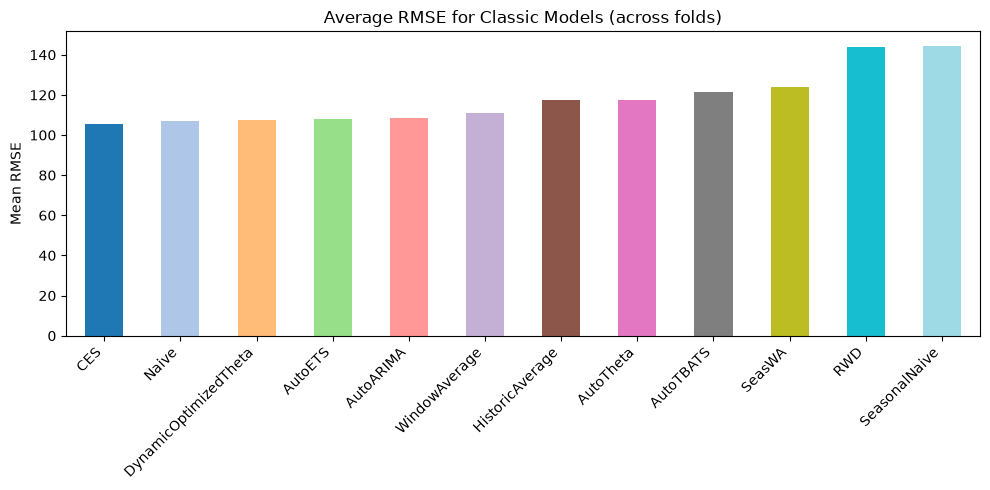

In [81]:
# Classic Models
mean_rmse = rmse_pivot.mean(axis=0).dropna().sort_values()
n = len(mean_rmse)
cmap = plt.get_cmap('tab20')                # robust getter
colors = [cmap(i / max(1, n-1)) for i in range(n)]
ax = mean_rmse.plot(kind='bar', figsize=(10,5), color=colors)
ax.set_ylabel('Mean RMSE')
ax.set_title('Average RMSE for Classic Models (across folds)')
plt.xticks(rotation=45, ha='right')
plt.xlabel("")
plt.tight_layout()
plt.show()

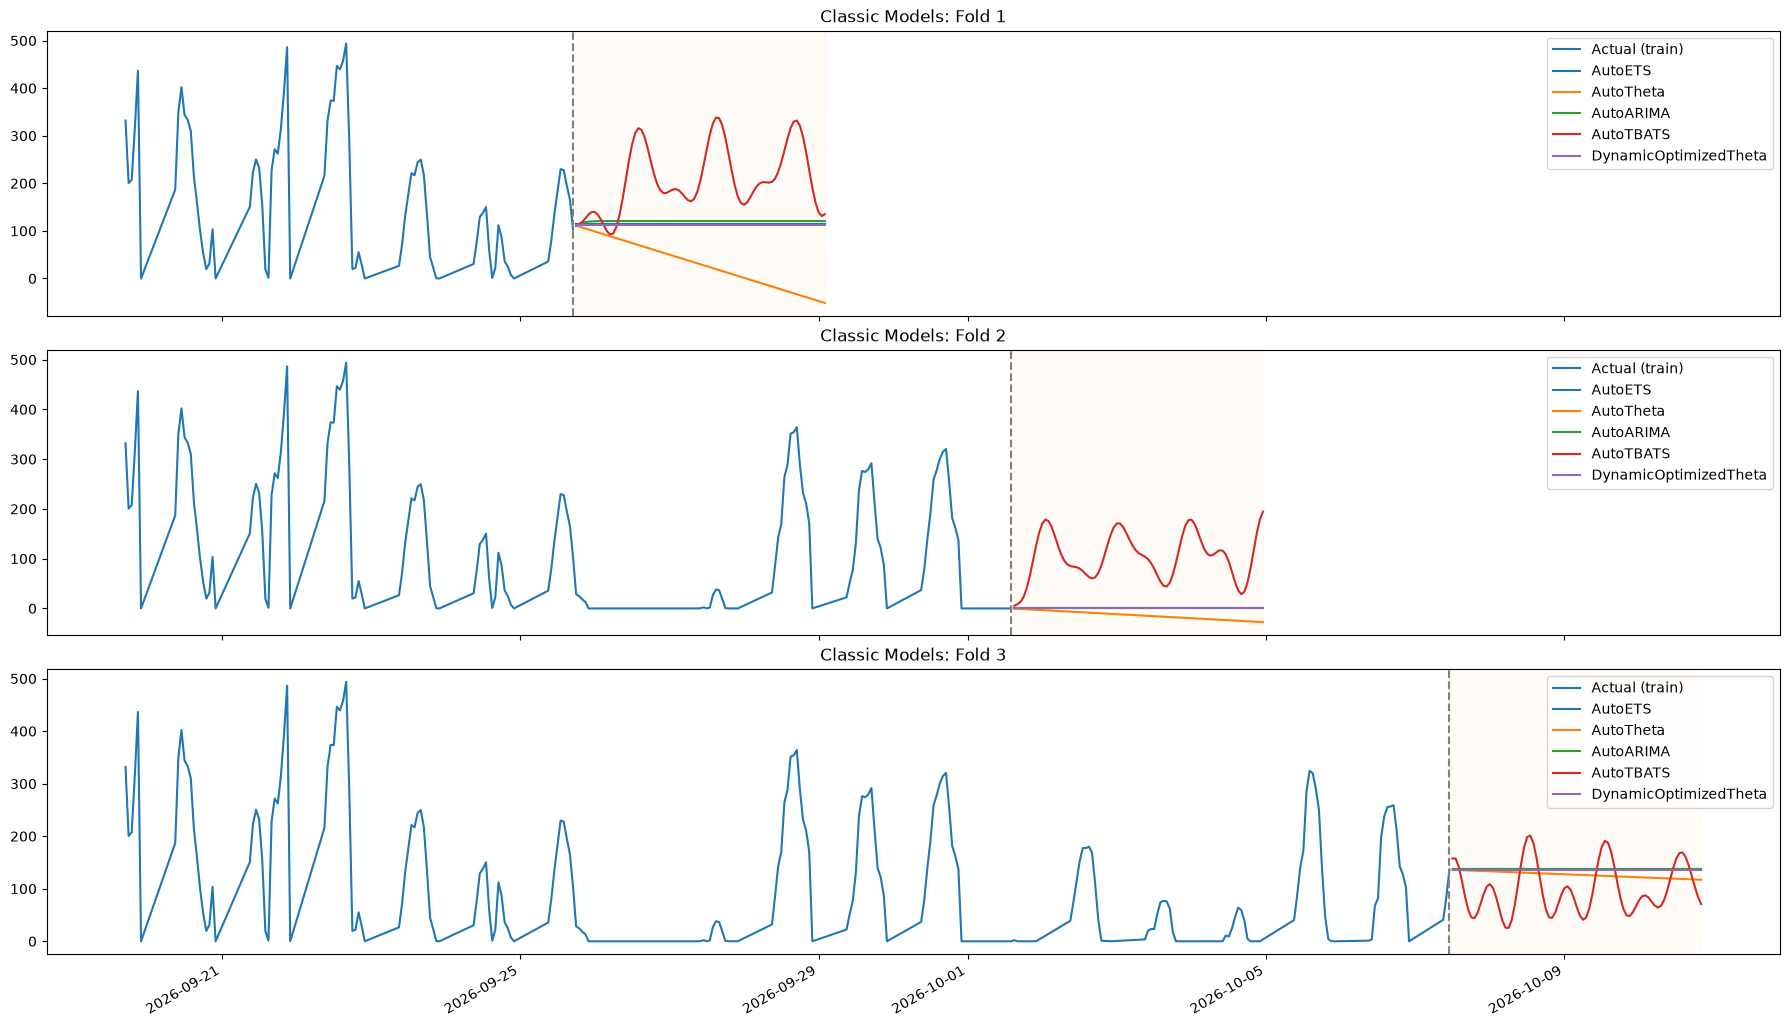

In [82]:
import matplotlib.dates as mdates
i = 0
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(18,12), sharex=True)

selecte_cols = ['AutoETS', 'AutoTheta','AutoARIMA','AutoTBATS','DynamicOptimizedTheta']
for train_idx, test_idx in tscv.split(series):
    train = series.iloc[train_idx].copy()
    predictions_sf = raw_result[i].loc[:,raw_result[i].columns != 'unique_id']
    predictions_sf.loc[:, "ds"] = pd.to_datetime(predictions_sf["ds"])
    predictions_sf = predictions_sf.set_index('ds').sort_index()

    axes[i].plot(train.index, train.values, label='Actual (train)', color='tab:blue')

    for col in selecte_cols:
        axes[i].plot(predictions_sf.index, predictions_sf[col], label=col)

    last_train_ts = train.index.max()
    axes[i].axvline(last_train_ts, color='gray', linestyle='--')
    axes[i].axvspan(last_train_ts, predictions_sf.index.max(), color='orange', alpha=0.03)

    axes[i].set_title(f'Classic Models: Fold {i+1}')
    axes[i].legend(loc='upper right')

    i += 1
    if i >= len(axes):
        break

plt.tight_layout()
fig.autofmt_xdate()
plt.show()

In [94]:
import lightgbm as lgb
X = x_occ
y = y_occ

cate_cols = ["semester_flag", "weekday", "opening_fraction"]

tscv = TimeSeriesSplit(n_splits=4, gap=0)

params = {
    "objective": "regression",
    "metric": ["rmse"],
    "boosting_type": "gbdt",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "feature_fraction": 0.9,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "verbosity": -1,
    "seed": 4130
}
num_boost_round = 1000
lgb_results = []
fold = 0

for train_index, test_index in tscv.split(X):
    fold += 1
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Create LightGBM dataset (categorical_feature accepts names)
    lgb_train = lgb.Dataset(X_train, label=y_train, categorical_feature=cate_cols, free_raw_data=False)
    lgb_test= lgb.Dataset(X_test, label=y_test, categorical_feature=cate_cols, free_raw_data=False)

    # Train model (no validation set)
    bst = lgb.train(
        params,
        train_set=lgb_train,
        num_boost_round=num_boost_round,
        callbacks=[lgb.early_stopping(stopping_rounds=25)],
        valid_sets=[lgb_test],
    )

    # Predict and compute RMSE
    y_pred = bst.predict(X_test)
    rmse = root_mean_squared_error(y_test, y_pred)

    lgb_results.append({"fold": fold, "rmse": rmse})


    print(f"Fold {fold} — train rows: {len(X_train)}, test rows: {len(X_test)}, RMSE: {rmse:.6f}")

# Summary
res_df = pd.DataFrame(lgb_results)
print("\nCross-fold RMSEs:")
print(res_df)
print(f'model std: {res_df["rmse"].std()} model mean: {res_df["rmse"].mean()}')

Training until validation scores don't improve for 25 rounds
Early stopping, best iteration is:
[65]	valid_0's rmse: 66.4354
Fold 1 — train rows: 85, test rows: 81, RMSE: 66.435389
Training until validation scores don't improve for 25 rounds
Early stopping, best iteration is:
[101]	valid_0's rmse: 28.1564
Fold 2 — train rows: 166, test rows: 81, RMSE: 28.156417
Training until validation scores don't improve for 25 rounds
Early stopping, best iteration is:
[105]	valid_0's rmse: 30.1914
Fold 3 — train rows: 247, test rows: 81, RMSE: 30.191392
Training until validation scores don't improve for 25 rounds
Early stopping, best iteration is:
[94]	valid_0's rmse: 28.1147
Fold 4 — train rows: 328, test rows: 81, RMSE: 28.114746

Cross-fold RMSEs:
   fold       rmse
0     1  66.435389
1     2  28.156417
2     3  30.191392
3     4  28.114746
model std: 18.832228784922595 model mean: 38.22448608219752


In [84]:
import lightgbm as lgb
import optuna
from optuna.visualization import plot_param_importances
from optuna.samplers import CmaEsSampler


def objective(trial, X, y, tscv = None):
  occ_rows = len(y)
  tscv = TimeSeriesSplit(n_splits=4, gap=0)
  cate_cols = ["semester_flag", "weekday", "opening_fraction"]
  r_n = int(occ_rows/2)

  params = {
      # Fixed Parameters
      'boosting_type': 'gbdt',
      'objective': 'regression',          # Change to 'regression' or 'multiclass' if needed
      'metric': ["rmse"],

      # Complexity Control (Crucial for Small Datasets)
      'max_depth': trial.suggest_int('max_depth',low = 2, high = r_n),   # Keep trees shallow to prevent memorizing data (default: -1)
      'num_leaves': trial.suggest_int('num_leaves',low = 2, high = 256),  # Must be strictly less than 2^max_depth (default: 31)
      'min_data_in_leaf': trial.suggest_int('min_data_in_leaf',low = 2, high = r_n),          # Small data requires a smaller threshold to allow splits (default: 20)
      'learning_rate': trial.suggest_float('learning_rate',low =0.01, high = 0.5),          # Lower rate gives more stable learning on small data

      # Subsampling (Adds Randomness)
      'feature_fraction': trial.suggest_float('feature_fraction',low =0.1, high = 1),        # Use a subset of features per tree (default: 1.0)
      'bagging_fraction': trial.suggest_float('bagging_fraction',low =0.1, high = 1),        # Use a subset of rows per iteration (default: 1.0)
      'bagging_freq': trial.suggest_int('bagging_freq',low = 2, high = 64),              # Perform bagging at every iteration

      # Regularization & Binning
      'lambda_l1': trial.suggest_float('lambda_l1',low =0.1, high = 10),               # L1 Regularization (Lasso)
      'lambda_l2': trial.suggest_float('lambda_l2',low =0.1, high = 10),               # L2 Regularization (Ridge)
      'max_bin':  trial.suggest_int('max_bin',low = 2, high = 256),                  # Fewer bins acts as a regularizer for small data (default: 255)

      'verbose': -1                   # Silences warnings about small data splits
  }

  num_boost_round = 1000
  results = []
  fold = 0

  for train_index, test_index in tscv.split(X):
      fold += 1
      X_train, X_test = X.iloc[train_index], X.iloc[test_index]
      y_train, y_test = y.iloc[train_index], y.iloc[test_index]

      # Create LightGBM dataset (categorical_feature accepts names)
      lgb_train = lgb.Dataset(X_train, label=y_train, categorical_feature=cate_cols, free_raw_data=False)
      lgb_test= lgb.Dataset(X_test, label=y_test, categorical_feature=cate_cols, free_raw_data=False)

      # Train model (no validation set)
      test_bst = lgb.train(
          params,
          train_set=lgb_train,
          num_boost_round=num_boost_round,
          callbacks=[lgb.early_stopping(stopping_rounds=30,verbose=False)],
          valid_sets=[lgb_test],
      )

      # Predict and compute RMSE
      y_pred = bst.predict(X_test)
      rmse = root_mean_squared_error(y_test, y_pred)

      results.append({"fold": fold, "rmse": rmse})

  # Summary
  res_df = pd.DataFrame(results)
  return res_df["rmse"].mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)

def logging_callback(study, frozen_trial, period=10):
  # Print period trials
  if (frozen_trial.number + 1) % period == 0:
    print(
        f"Trial {frozen_trial.number + 1} finished with value: {frozen_trial.value}"
        f" and params: {frozen_trial.params}"
    )

# 3. Pass the callback to study.optimize()
study = optuna.create_study(direction="minimize",
                            sampler=CmaEsSampler(n_startup_trials=20))
study.optimize(
    lambda trial: objective(trial, X, y, tscv =tscv ),
    n_trials=100,
    callbacks=[logging_callback]
)

Trial 10 finished with value: 18.448654726918402 and params: {'max_depth': 186, 'num_leaves': 63, 'min_data_in_leaf': 181, 'learning_rate': 0.0541418491091461, 'feature_fraction': 0.7104686279115363, 'bagging_fraction': 0.3657721271328145, 'bagging_freq': 22, 'lambda_l1': 5.31162453085523, 'lambda_l2': 0.5250757990385269, 'max_bin': 225}
Trial 20 finished with value: 18.448654726918402 and params: {'max_depth': 16, 'num_leaves': 25, 'min_data_in_leaf': 119, 'learning_rate': 0.31254978595318406, 'feature_fraction': 0.9365272048893881, 'bagging_fraction': 0.8989790046587027, 'bagging_freq': 34, 'lambda_l1': 9.760733515430116, 'lambda_l2': 6.4702760019923415, 'max_bin': 177}
Trial 30 finished with value: 18.448654726918402 and params: {'max_depth': 113, 'num_leaves': 17, 'min_data_in_leaf': 110, 'learning_rate': 0.17647762087251204, 'feature_fraction': 0.690529515247332, 'bagging_fraction': 0.5175876426998576, 'bagging_freq': 39, 'lambda_l1': 6.689658638886127, 'lambda_l2': 4.883990565548

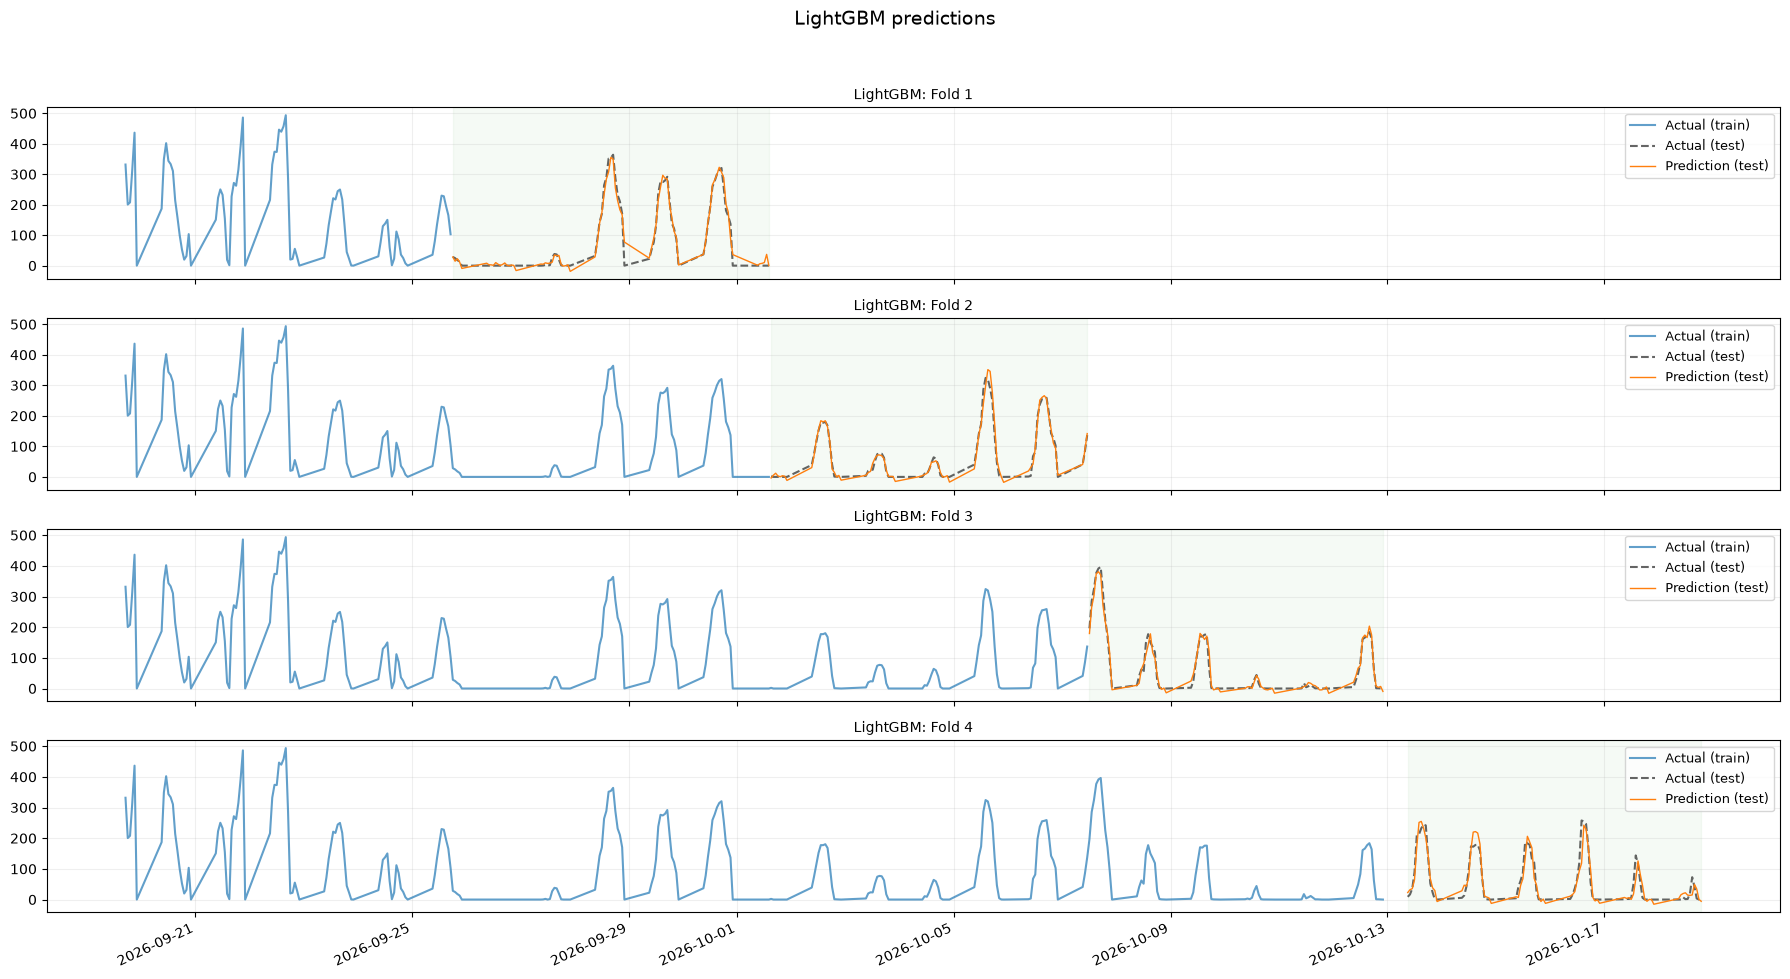

model std: 6.529753423952664 model mean: 18.448654726918402


count    409.000000
mean      98.239633
std      116.091913
min        0.000000
25%        0.675676
50%       42.312704
75%      173.537118
max      493.786667
Name: occupant_count, dtype: float64

In [85]:
final_params = {
    "objective": "regression",
    "metric": ["rmse","l1"],
    "verbose": -1,
    **study.best_params,
}

X = x_occ
y = y_occ

lgb_best_results = []
fold = 0
tscv = TimeSeriesSplit(n_splits=4, gap=0)

n_folds = 4

fig, axes = plt.subplots(nrows=n_folds, ncols=1, figsize=(18, 2.4 * n_folds), sharex=True)


for train_index, test_index in tscv.split(X):
    fold += 1
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Create LightGBM dataset (categorical_feature accepts names)
    lgb_train = lgb.Dataset(X_train, label=y_train, categorical_feature=cate_cols, free_raw_data=False)
    lgb_test= lgb.Dataset(X_test, label=y_test, categorical_feature=cate_cols, free_raw_data=False)

    # Train model (no validation set)
    test_bst = lgb.train(
        final_params,
        train_set=lgb_train,
        num_boost_round=num_boost_round,
        callbacks=[lgb.early_stopping(stopping_rounds=30,verbose=False)],
        valid_sets=[lgb_test],
    )

    # Predict and compute RMSE
    y_pred = bst.predict(X_test)
    rmse = root_mean_squared_error(y_test, y_pred)

    lgb_best_results.append({"fold": fold, "rmse": rmse})

    ax = axes[fold-1]
    # plot train actuals
    ax.plot(y_train.index, y_train.values.ravel(), label="Actual (train)", color="tab:blue", alpha=0.7)
    # plot test actuals (dashed) and predictions
    ax.plot(y_test.index, y_test.values.ravel(), label="Actual (test)", color="black", linestyle="--", alpha=0.6)
    ax.plot(y_test.index, y_pred, label="Prediction (test)", color="tab:orange", linewidth=1)

    # Shade the test region
    ax.axvspan(y_test.index.min(), y_test.index.max(), color="green", alpha=0.04)

    ax.set_title(f"LightGBM: Fold {fold}", fontsize=10, pad=6)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)


fig.suptitle("LightGBM predictions", fontsize=14, y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.95])  # reserve space at top for suptitle
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=25, ha="right")
plt.show()

# Summary
res_df = pd.DataFrame(lgb_best_results)
print(f'model std: {res_df["rmse"].std()} model mean: {res_df["rmse"].mean()}')

y_occ.describe()



In [95]:
print("Tuned LightGBM Error")
print(res_df)
print(f'model std: {res_df["rmse"].std()} model mean: {res_df["rmse"].mean()}')

Tuned LightGBM Error
   fold       rmse
0     1  66.435389
1     2  28.156417
2     3  30.191392
3     4  28.114746
model std: 18.832228784922595 model mean: 38.22448608219752
